# Solar system

The Sun, Earth, Jupiter, and Halley's comet, attracted to each other by gravity. AutoPas has no functor for this, so this notebook defines one in Python and hands it to the simulation.

The units keep the numbers simple: Lengths are in astronomical units, masses in solar masses, and the gravitational constant is 1. One year then takes $2\pi$ time units.

The whole notebook takes less than a minute on a laptop, most of it for drawing the GIFs. To run this notebook, install the module with `pip install ".[plot]"` and `jupyterlab` into your environment.

In [1]:
import math
import os

# Four bodies are not enough work to share: With 10 threads, this ran 14 times slower than with one.
os.environ["OMP_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from matplotlib.animation import FuncAnimation

import autopas as ap

## The bodies

Everything starts on the axes: Earth and Jupiter on their orbits, the comet at its farthest point from the Sun. Each body gets a particle type of its own, because the mass of a particle is a property of its type.

In [2]:
names = ["Sun", "Earth", "Jupiter", "Halley"]
positions = np.array([[0.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 5.36, 0.0], [34.75, 0.0, 0.0]])
velocities = np.array([[0.0, 0.0, 0.0], [-1.0, 0.0, 0.0], [-0.425, 0.0, 0.0], [0.0, 0.0296, 0.0]])
masses = np.array([1.0, 3.0e-6, 9.55e-4, 1.0e-14])

# With the Sun at rest, the system as a whole would drift. Work in the frame in which its center of mass stands still.
velocities -= masses @ velocities / masses.sum()

## The functor

A functor written in Python derives from `ap.PairwiseFunctor` and implements `aos`, which AutoPas calls once per pair of particles. Newton's third law means each pair only has to be computed once, which is why this one turns off the other mode. The potential energy is optional, and ends up in the history of the simulation.

In [3]:
class Gravity(ap.PairwiseFunctor):
    """Newton's law of gravitation, with a gravitational constant of 1."""

    def __init__(self, masses):
        super().__init__(allows_non_newton3=False)
        self.masses = masses
        self.energy = 0.0

    def init_traversal(self):
        self.energy = 0.0

    def aos(self, i, j, newton3):
        separation = j.r - i.r
        distance = math.sqrt(separation.dot(separation))
        mass_product = self.masses[i.type_id] * self.masses[j.type_id]
        force = mass_product / distance**3 * separation
        i.add_f(force)
        j.sub_f(force)
        self.energy -= mass_product / distance

    def potential_energy(self):
        return self.energy

## The simulation

Gravity has no finite range, so this needs the `DirectSum` container, which is the only one that goes through all pairs. The others save work by only looking at nearby particles, and would have to treat almost everything as nearby here.

AutoPas still requires a cutoff, and only hands pairs closer than that to the functor. So it has to be larger than any distance between two bodies, which we check further down. With a single algorithm configuration to choose from, no tuning takes place.

In [4]:
RECORD_INTERVAL = 10
DELTA_T = 0.014

config = {
    # The simulated system: Open space, with the domain only being large enough
    "box-min": [-50.0, -50.0, -50.0],
    "box-max": [50.0, 50.0, 50.0],
    "boundary-type": ["none", "none", "none"],
    "cutoff": 60.0,  # Larger than any distance between two bodies. Together with the skin, this has to fit into the box.
    "deltaT": DELTA_T,
    # Gravity only needs the masses, but a type also requires the Lennard-Jones parameters
    "Sites": {type_id: {"mass": float(mass), "epsilon": 1.0, "sigma": 1.0} for type_id, mass in enumerate(masses)},
    # What AutoPas may choose from: One configuration
    "container": ["DirectSum"],
    "traversal": ["ds_sequential"],
    "data-layout": ["AoS"],
    "newton3": ["enabled"],
    # A particle may move at most skin / frequency / 2 per iteration
    "verlet-skin-radius": 1.0,
    "verlet-rebuild-frequency": 10,
    "log-level": "warn",
}

ap_instance = ap.AutoPas(config, functors=Gravity(masses), history_interval=RECORD_INTERVAL)
ap_instance.add_particles(positions, velocities=velocities, type_ids=np.arange(len(names)))
ap_instance.current_configuration

{'pairwise': '{Interaction Type: pairwise , Container: DirectSum , CellSizeFactor: 1.000000 , Traversal: ds_sequential , Load Estimator: none , Data Layout: AoS , Newton 3: enabled , VectorizationPattern: NotApplicable}'}

Calling the object resumes the simulation from where it stopped, so we can record the positions in between. This run covers a bit more than one orbit of the comet, which takes about 75 years. The plots below only use these records and do not advance the simulation anymore.

In [5]:
ITERATIONS_PER_YEAR = 2.0 * math.pi / DELTA_T
records = int(85 * ITERATIONS_PER_YEAR / RECORD_INTERVAL)

trajectory = [ap_instance.positions]
for _ in range(records):
    ap_instance(RECORD_INTERVAL)
    trajectory.append(ap_instance.positions)
trajectory = np.array(trajectory)  # Shape: records, bodies, xyz
years = np.arange(records + 1) * RECORD_INTERVAL / ITERATIONS_PER_YEAR

ap_instance.iteration, trajectory.shape

(38140, (3815, 4, 3))

## The orbits

The animation draws the orbits up to each record. The sizes of the orbits differ a lot, so we look at them at two scales.

First the whole system. One frame is about one year, which is why Earth seems to stand still. The comet spends most of its time far out, and rushes past the Sun in the middle of its orbit.

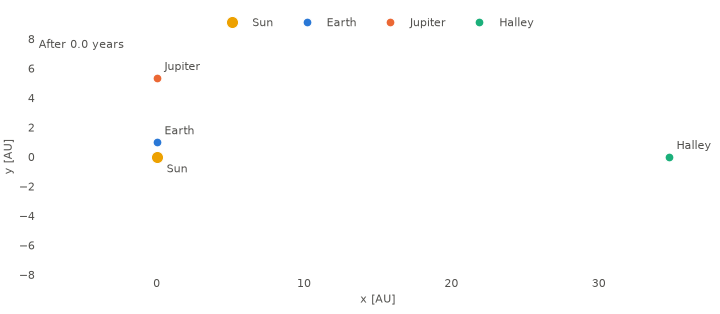

In [6]:
COLORS = {"Sun": "#eda100", "Earth": "#2a78d6", "Jupiter": "#eb6834", "Halley": "#1baf7a"}
INK = "#52514e"


def orbits_as_gif(path, shown_records, *, xlim, ylim, width, fps):
    """Shows the orbits up to each of the given records as a GIF."""
    height = width * (ylim[1] - ylim[0]) / (xlim[1] - xlim[0]) + 0.8  # The legend and the axis labels need some room
    figure, ax = plt.subplots(figsize=(width, height), constrained_layout=True)
    ax.set(xlim=xlim, ylim=ylim, aspect="equal")
    ax.set_xlabel("x [AU]", color=INK)
    ax.set_ylabel("y [AU]", color=INK)
    ax.tick_params(colors=INK, length=0)
    for side in ax.spines.values():
        side.set_visible(False)

    orbits = [ax.plot([], [], color=COLORS[name], linewidth=1.5)[0] for name in names]
    bodies = [
        ax.plot([], [], "o", color=COLORS[name], markeredgecolor="white", markersize=11 if name == "Sun" else 8,
                label=name)[0]
        for name in names
    ]
    labels = [
        # Earth stays close to the Sun, so their labels go on different sides
        ax.annotate(name, (0.0, 0.0), xytext=(9, -14) if name == "Sun" else (7, 7), textcoords="offset points",
                    color=INK, annotation_clip=True)
        for name in names
    ]
    ax.legend(handles=bodies, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=len(names), frameon=False,
              labelcolor=INK)
    elapsed = ax.text(0.0, 1.0, "", transform=ax.transAxes, verticalalignment="top", color=INK)

    def update(record):
        for body, (orbit, marker, label) in enumerate(zip(orbits, bodies, labels)):
            x, y = trajectory[: record + 1, body, :2].T
            orbit.set_data(x, y)
            marker.set_data(x[-1:], y[-1:])
            label.xy = (x[-1], y[-1])
        elapsed.set_text(f"After {years[record]:.1f} years")
        return [*orbits, *bodies, *labels, elapsed]

    animation = FuncAnimation(figure, update, frames=shown_records)
    animation.save(path, writer="pillow", fps=fps, dpi=80)
    plt.close(figure)
    return Image(filename=path)


RECORDS_PER_YEAR = round(ITERATIONS_PER_YEAR / RECORD_INTERVAL)

orbits_as_gif(
    "solarSystem_whole.gif",
    range(0, records + 1, RECORDS_PER_YEAR),
    xlim=(-8.0, 38.0),
    ylim=(-8.0, 8.0),
    width=9.0,
    fps=8,
)

Now the inner part, at much finer steps, during the time in which the comet passes the Sun. Its point of closest approach is inside the orbit of Earth.

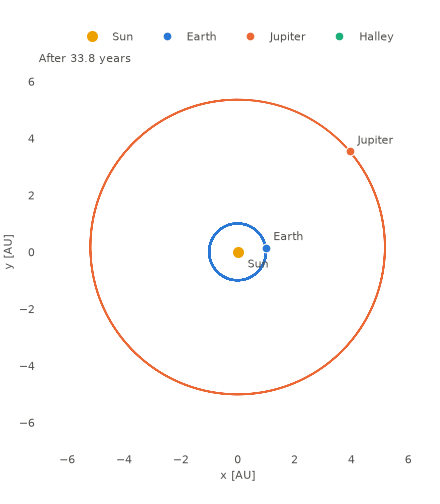

In [7]:
distance_to_sun = np.linalg.norm(trajectory[:, names.index("Halley")] - trajectory[:, names.index("Sun")], axis=1)
closest_approach = int(distance_to_sun.argmin())

orbits_as_gif(
    "solarSystem_inner.gif",
    range(closest_approach - 150, closest_approach + 150, 2),
    xlim=(-7.0, 7.0),
    ylim=(-7.0, 7.0),
    width=5.5,
    fps=15,
)

## Is this right?

Three checks: Did the cutoff stay out of the way? Do the orbital periods match [Kepler's third law](https://en.wikipedia.org/wiki/Kepler%27s_laws_of_planetary_motion), which gives $a^{3/2}$ years for a semi-major axis $a$? And is the total energy conserved?

In [8]:
distances = np.linalg.norm(trajectory[:, :, None] - trajectory[:, None], axis=-1)
print(f"Largest distance between two bodies: {distances.max():.1f} AU, cutoff: {ap_instance.cutoff} AU\n")


def simulated_period(body):
    """How long the body takes for its first full turn around the Sun."""
    relative = trajectory[:, body] - trajectory[:, names.index("Sun")]
    angle = np.unwrap(np.arctan2(relative[:, 1], relative[:, 0]))
    return np.interp(angle[0] + 2.0 * math.pi, angle, years)


def kepler_period(body):
    """The period following from the initial state of the body, as if the Sun were alone with it."""
    distance = np.linalg.norm(positions[body] - positions[0])
    speed_squared = np.sum((velocities[body] - velocities[0]) ** 2)
    semi_major_axis = 1.0 / (2.0 / distance - speed_squared)
    return semi_major_axis**1.5


print(f"{'':8} {'simulated':>10} {'Kepler':>10}  [years]")
for body in range(1, len(names)):
    print(f"{names[body]:8} {simulated_period(body):10.2f} {kepler_period(body):10.2f}")

history = ap_instance.history
energy = history["potential_energy"] + history["kinetic_energy"]
print(f"\nLargest relative change of the total energy: {np.abs((energy - energy[0]) / energy[0]).max():.1e}")

Largest distance between two bodies: 40.3 AU, cutoff: 60.0 AU

          simulated     Kepler  [years]
Earth          1.00       1.00
Jupiter       11.82      11.84
Halley        74.84      74.11

Largest relative change of the total energy: 5.7e-08


The comet is off by about 1%, because Kepler's law assumes it is alone with the Sun. In that case, this simulation gives 74.2 years. Here, Jupiter pulls on it, which also explains why its orbit does not quite close in the first animation.